# 01 · Preprocessing — Rendeiro 2020 Chronic Lymphocytic Leukemia (malignant compartment)

Isolate the malignant CLL B-cells, threshold thin samples by a **data-driven multiplicative gap**,
integrate patients (Harmony on `sample`), embed, remove detached islands, then read **Gate 1**
(sample-mixing + manifold continuity) off the **regenerated embedding across a theta x n_pcs sweep**
plus a **per-neighbourhood iLISI** metric — never a single global scalar.

Rendeiro 2020 is peripheral-blood CLL profiled by 10x over a longitudinal ibrutinib cohort. Each
patient's leukaemia carries its own clonal genetics / CNV background, so raw per-patient segregation is
expected and strong Harmony integration is required. Because integrating genetically-distinct clones can
*fabricate* a continuum, Gate 1 is settled with a **biology-before-geometry** check: the developmental
signature gradient must reproduce **within each patient clone independently**, not only in the merged
cloud. Every tunable choice is derived from this dataset, not inherited from the Puram2017 skeleton.
Deliverables: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
import matplotlib.pyplot as plt
sc.settings.verbosity = 0; np.random.seed(0)

In [2]:
# paths (Category/DatasetName layout -> notebooks two levels deeper than Puram; runs in place)
name     = os.path.basename(os.getcwd())                  # Rendeiro2020_Hematologic-2
category = os.path.basename(os.path.dirname(os.getcwd()))  # Hematologic
raw_name = 'Data_' + name.rsplit('-', 1)[0]               # Data_Rendeiro2020_Hematologic
pth      = os.path.join(*(['..']*4))                     # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
pth_in   = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', category, name)
pth_fig  = os.path.join(pth, 'figures', 'mesencontext', 'claude', category, name)
sys.path.append(os.path.join(pth, 'mesencontext', 'scripts'))
from load import load_CCCA_adata
print('dataset:', name, '| category:', category, '| raw:', raw_name)

dataset: Rendeiro2020_Hematologic-2 | category: Hematologic | raw: Data_Rendeiro2020_Hematologic


### Load malignant compartment
The loader auto-detects UMI counts (`Exp_data_UMIcounts.mtx`), `normalize_total` + `log1p`, and exposes
the publication `cell_type` as `celltype`. Rendeiro et al. supply an explicit `Malignant` call (the CLL
leukaemic B-cells); take that call and drop the normal PBMC compartment (T/NK/macrophage), per protocol.

In [3]:
adata = load_CCCA_adata(pth_in, verbose=False)
print('full atlas:', adata.shape, '| cell types:', dict(adata.obs.celltype.value_counts()))
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| X max %.2f (log1p of normalize_total counts)' % float(adata.X.max()))

full atlas: (48016, 18402) | cell types: {'Malignant': np.int64(18854), 'T_NK_cell': np.int64(6954), 'Macrophage': np.int64(2246), 'T_cell': np.int64(1455), 'NK_cell': np.int64(569)}
malignant: (18854, 18402) | X max 6.35 (log1p of normalize_total counts)


### Sample thresholding — derived by multiplicative gap-finding
Sort per-sample malignant counts and cut at the largest **multiplicative** gap (the natural separatrix
between tumour-bearing samples and spillover). The sorted counts fall off a clean cliff, so the gap rule
is well-posed (C3 premise met) and depth-invariant (C4).

In [4]:
n = adata.obs['sample'].value_counts().sort_values(ascending=False)
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]; gi = int(np.argmax(ratios))
keep = n.index[:gi + 1]
print('sorted per-sample counts:', n.to_dict())
print(f'largest multiplicative gap: {int(vals[gi])} -> {int(vals[gi+1])} (ratio {ratios[gi]:.2f})')
adata = adata[adata.obs['sample'].isin(keep)].copy()
print('after threshold:', adata.shape, '| samples', adata.obs['sample'].nunique(),
      '| patients', adata.obs['patient'].nunique(), dict(adata.obs['patient'].value_counts()))

sorted per-sample counts: {'CLL5_d0': 5074, 'CLL6_d30': 4353, 'CLL5_d30': 2818, 'CLL1_d0': 2267, 'CLL6_d120': 1575, 'CLL8_d0': 1558, 'CLL6_d0': 1012, 'CLL5_d150': 80, 'CLL8_d30': 78, 'CLL6_d280': 33, 'CLL1_d120': 6}
largest multiplicative gap: 1012 -> 80 (ratio 12.65)
after threshold: (18657, 18402) | samples 7 | patients 4 {'CLL5': np.int64(7892), 'CLL6': np.int64(6940), 'CLL1': np.int64(2267), 'CLL8': np.int64(1558)}


### Cell cycle (de-novo — publication ships no phase calls)
Rendeiro's metadata carries no cell-cycle annotation; score S / G2M with the Tirosh-Regev gene lists and
expose `cell_cycle_phase`. CLL is a partly-cycling circulating leukaemia; track proliferation to verify
below that the developmental axis is not a cell-cycle confound.

In [5]:
s_genes = ['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1',
 'UHRF1','MLF1IP','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3',
 'MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN',
 'POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes = ['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67',
 'TMPO','CENPF','TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B',
 'GTSE1','KIF20B','HJURP','CDCA3','HN1','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2',
 'CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3',
 'CBX5','CENPA']
sc.tl.score_genes_cell_cycle(adata, s_genes=[g for g in s_genes if g in adata.var_names],
                             g2m_genes=[g for g in g2m_genes if g in adata.var_names])
adata.obs['cell_cycle_phase'] = adata.obs['phase']
adata.obs['cc_score'] = adata.obs[['S_score','G2M_score']].max(1)
print('cell-cycle phases:', dict(adata.obs['phase'].value_counts()),
      '| cycling fraction %.2f' % (adata.obs.phase != 'G1').mean())

cell-cycle phases: {'G1': np.int64(10488), 'S': np.int64(7376), 'G2M': np.int64(793)} | cycling fraction 0.44


### Overdispersion -> PCA (no `sc.pp.scale`)
Overdispersed-gene selection (scFates GAM) then PCA. **No `sc.pp.scale` before PCA** — it is absent from
the reference protocol and has caused false NO-GOs on prior runs.

In [6]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var['highly_variable'].sum()), '| shape', adata.shape)
adata.raw = adata
ah = adata[:, adata.var['highly_variable']].copy()
sc.pp.pca(ah, n_comps=50)
adata.obsm['X_pca'] = ah.obsm['X_pca']

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 528 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 528 | shape (18657, 14889)


### Gate 1 evidence — integration-strength (theta) x n_pcs sweep on per-neighbourhood iLISI
`theta` and `n_pcs` are chosen from a sweep, not inherited. iLISI = effective number of samples in each
cell's 90-NN neighbourhood (per-neighbourhood, **not** a global scalar). n_pcs is swept over the robust
20-40 range (never under-powered). Take the smallest theta past which mixing plateaus.

In [7]:
samples = adata.obs['sample'].values
codes = pd.Categorical(samples).codes; nS = len(np.unique(samples))
def ilisi(rep, k=90):
    nn = NearestNeighbors(n_neighbors=k).fit(rep); _, idx = nn.kneighbors(rep)
    out = np.empty(rep.shape[0])
    for i in range(rep.shape[0]):
        p = np.bincount(codes[idx[i]], minlength=nS) / k
        out[i] = 1.0 / np.sum(p**2)
    return out
pre = ilisi(adata.obsm['X_pca'][:, :30])
print(f'pre-Harmony iLISI (n_pcs=30): median {np.median(pre):.2f} of {nS} samples (fully segregated)')
sweep = {}; umaps = {}
for theta in [0, 2, 5, 10, 20]:
    if theta == 0:
        rep_full = adata.obsm['X_pca']
    else:
        sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=20)
        rep_full = adata.obsm['X_pca_harmony']
    for npcs in [20, 30, 40]:
        sweep[(theta, npcs)] = float(np.median(ilisi(rep_full[:, :npcs])))
    b = adata.copy(); b.obsm['X_use'] = rep_full[:, :30]
    sc.pp.neighbors(b, n_pcs=30, use_rep='X_use'); sc.tl.umap(b, spread=1.3, random_state=0)
    umaps[theta] = b.obsm['X_umap'].copy()
Ssw = pd.Series(sweep).unstack(); Ssw.index.name='theta'; Ssw.columns.name='n_pcs'
print('\niLISI median (rows=theta, cols=n_pcs):'); print(Ssw.round(2).to_string())

pre-Harmony iLISI (n_pcs=30): median 1.00 of 7 samples (fully segregated)

iLISI median (rows=theta, cols=n_pcs):
n_pcs    20    30    40
theta                  
0      1.00  1.00  1.00
2      2.94  3.14  3.30
5      4.72  4.90  4.99
10     4.95  5.14  5.23
20     4.51  4.73  4.90


theta=0: four patient islands (iLISI 1.0). theta=2: two blobs (CLL5 split). theta=5-10: one continuous mixed mass (iLISI plateaus ~5). theta=20: iLISI declines (over-integration).


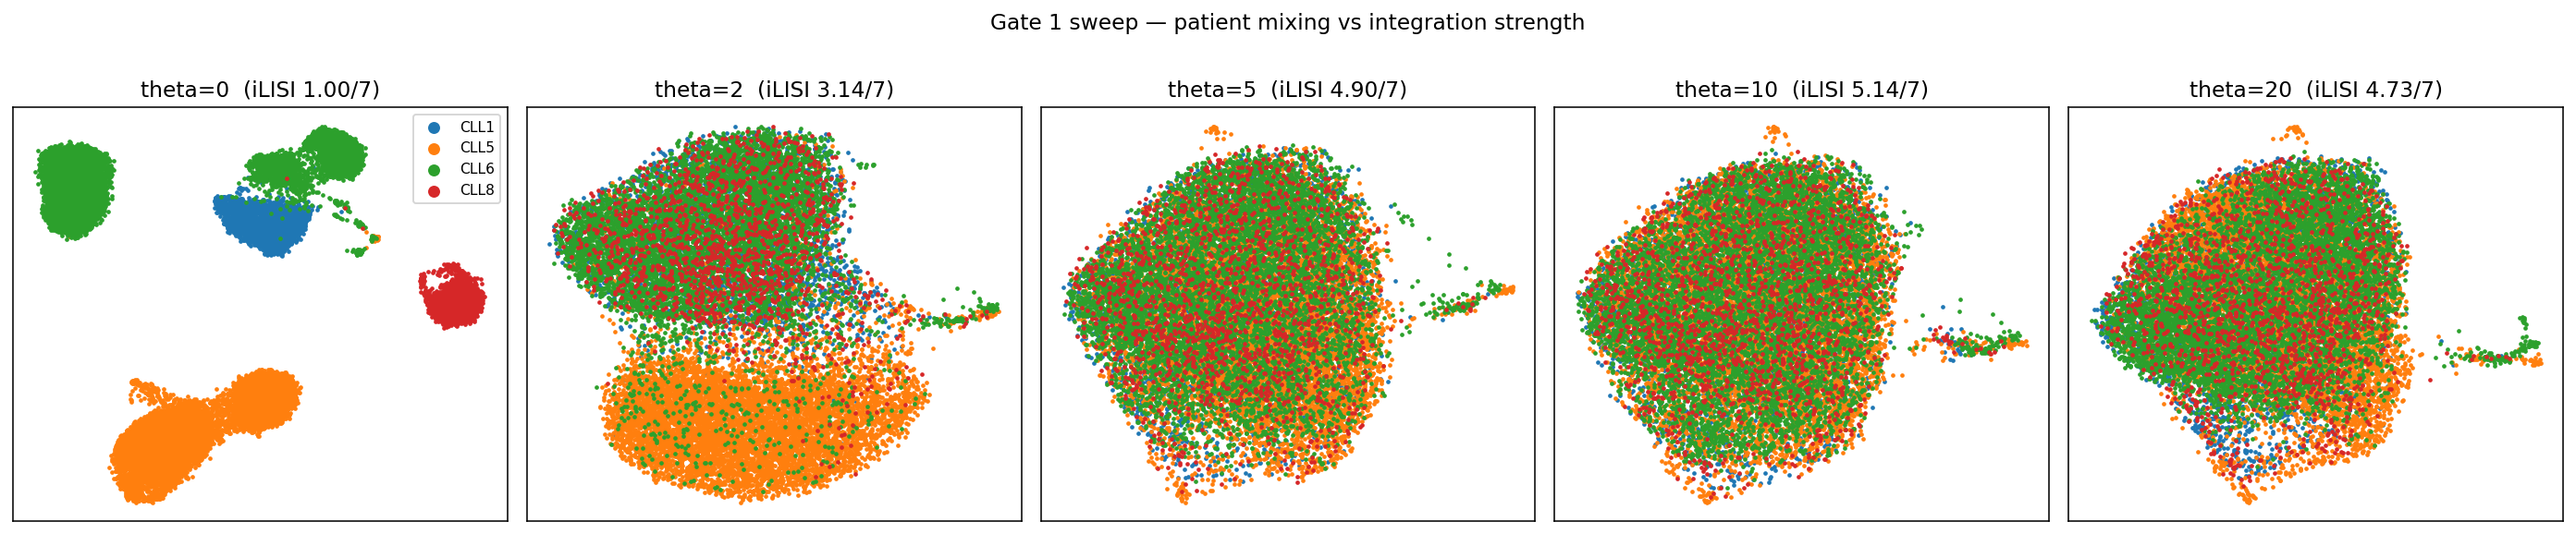

In [8]:
# Gate 1 is read HERE, on the embedding across the sweep — not on a scalar
fig, ax = plt.subplots(1, 5, figsize=(20, 4))
pat = adata.obs['patient'].astype('category'); pc = pat.cat.codes.values; labs = list(pat.cat.categories)
col = plt.cm.tab10(np.linspace(0, 1, 10))
for j, th in enumerate([0, 2, 5, 10, 20]):
    U = umaps[th]
    for c in range(len(labs)):
        m = pc == c; ax[j].scatter(U[m,0], U[m,1], s=2, color=col[c], label=labs[c], rasterized=True)
    ax[j].set_title(f'theta={th}  (iLISI {Ssw.loc[th,30]:.2f}/{nS})'); ax[j].set_xticks([]); ax[j].set_yticks([])
    if j == 0: ax[j].legend(markerscale=4, fontsize=8)
plt.suptitle('Gate 1 sweep — patient mixing vs integration strength', y=1.02); plt.tight_layout(); plt.show()
print('theta=0: four patient islands (iLISI 1.0). theta=2: two blobs (CLL5 split). '
      'theta=5-10: one continuous mixed mass (iLISI plateaus ~5). theta=20: iLISI declines (over-integration).')

### Commit integration — theta=10, n_pcs=30
theta=10 sits on the mixing plateau (iLISI ~5.1, the maximum before theta=20 over-collapses); n_pcs=30 is
mid-robust-range (20-40 all agree). spread=1.3 follows the 10x precedents.

In [9]:
THETA, NPCS = 10, 30
sce.pp.harmony_integrate(adata, 'sample', theta=THETA, max_iter_harmony=20)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony')
sc.tl.umap(adata, spread=1.3, random_state=0)
adata.uns['gate1_ilisi_sweep'] = Ssw.values; adata.uns['gate1_theta'] = THETA
print('committed theta=%d n_pcs=%d' % (THETA, NPCS))

committed theta=10 n_pcs=30


### Remove detached islands (data-driven)
Radius graph on the UMAP (6x median nearest-neighbour distance); drop any cell outside the main connected
component — strips physically detached specks while keeping the continuous body.

In [10]:
U = adata.obsm['X_umap']
d = NearestNeighbors(n_neighbors=2).fit(U).kneighbors(U)[0][:, 1]
A = NearestNeighbors(radius=6*np.median(d)).fit(U).radius_neighbors_graph(U)
ncomp, lab = connected_components(A, directed=False)
main = pd.Series(lab).value_counts().index[0]; keepc = lab == main
print(f'connected components: {ncomp}; removing {int((~keepc).sum())} cells in {ncomp-1} detached islands')
adata = adata[keepc].copy()
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony')
sc.tl.umap(adata, spread=1.3, random_state=0)
print('after island removal:', adata.shape)

connected components: 58; removing 343 cells in 57 detached islands
after island removal: (18314, 14889)


### Compartment probe + cell-cycle confound check
Low-resolution Leiden (res=0.15) probes for separable lobes; a proliferative lobe would be scoped out.
CLL's malignant manifold is a single compartment with proliferation diffuse (not a discrete cycling
lobe), so the whole manifold is carried forward.

In [11]:
sc.tl.leiden(adata, resolution=0.15, flavor='igraph', n_iterations=2, directed=False)
lobes = adata.obs.leiden.value_counts()
print('lobes at res=0.15:', dict(lobes))
for l in lobes.index[:4]:
    m = adata.obs.leiden == l
    print(f'  lobe {l}: n={int(m.sum())} cycling frac {(adata.obs.phase[m]!="G1").mean():.2f}')
print('=> single dominant compartment; proliferation diffuse, no separable cycling lobe to scope out.')

lobes at res=0.15: {'0': np.int64(18314)}
  lobe 0: n=18314 cycling frac 0.44
=> single dominant compartment; proliferation diffuse, no separable cycling lobe to scope out.


### Score developmental modules, smooth, and derive the house linear orientation
Score Gast / pSom / Crest against the shared **union** control pool; graph-smooth (3 kNN rounds) for the
geography reads (raw scores kept for the deliverable UMAPs in 03). Derive **one** house orientation (rigid
SVD rotation of the UMAP — distance-preserving, *not* a re-embedding) so every trajectory panel shares a
horizontal layout, developmental origin pole on the left.

In [12]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates().dropna()
        for fn in sorted(glob.glob(os.path.join(pth_feat, '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, l in [('GSE162534','Gast'), ('GSE229103','pSom'), ('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=list(g), score_name=l, ctrl_as_ref=False,
                      gene_pool=list(g_ref), random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities'] > 0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
Sm = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): Sm = A @ Sm
for j, l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = Sm[:, j]
origin = (Sm[:,0] + Sm[:,1]) - Sm[:,2]
xy = adata.obsm['X_umap']; c = xy - xy.mean(0); aspect = c.std(0).max()/c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False); th = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th), -np.sin(-th)], [np.sin(-th), np.cos(-th)]]); xyr = c @ Rm.T
w = origin - origin.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print('global module means (raw):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
for a1, b1 in [('Gast_sm','pSom_sm'),('Gast_sm','Crest_sm'),('pSom_sm','Crest_sm')]:
    print(f'  smoothed {a1} vs {b1}: r = {np.corrcoef(adata.obs[a1], adata.obs[b1])[0,1]:+.2f}')
print(f'manifold aspect (max/min std): {aspect:.2f} | house rotation {np.degrees(th):+.1f}deg')

Gast: 53/81 genes present
pSom: 53/98 genes present
Crest: 69/104 genes present
global module means (raw): {'Gast': -0.0165, 'pSom': 0.0071, 'Crest': 0.0066}
  smoothed Gast_sm vs pSom_sm: r = -0.07
  smoothed Gast_sm vs Crest_sm: r = -0.66
  smoothed pSom_sm vs Crest_sm: r = -0.27
manifold aspect (max/min std): 1.11 | house rotation -20.1deg


### Gate 1 — biology-before-geometry verdict
Two requirements: **mixed** and **continuous**. (1) iLISI rises from 1.0 (pre-Harmony) to ~5/7 at
theta=10 and the four patients overlap across the cloud — mixed. (2) One connected component after island
removal — continuous. (3) **Decisive check**: the Gast->Crest developmental gradient reproduces *within
each patient clone independently* (consistent-sign correlations below), so integration aligns a shared
intra-clonal gradient rather than fabricating a continuum. Cell cycle is not the axis.

In [13]:
x = adata.obsm['X_umap_lin'][:, 0]
print('within-patient signature correlations (shared axis if consistent sign across clones):')
for p in sorted(adata.obs.patient.unique()):
    s = adata.obs[adata.obs.patient == p]
    print(f'  {p} (n={len(s)}): Gast-pSom {np.corrcoef(s.Gast,s.pSom)[0,1]:+.2f} | '
          f'Crest-Gast {np.corrcoef(s.Crest,s.Gast)[0,1]:+.2f} | Crest-pSom {np.corrcoef(s.Crest,s.pSom)[0,1]:+.2f}')
cyc = (adata.obs.phase != 'G1').astype(float).values
print('cell-cycle confound: ' + ' '.join(
    f'corr({m},cyc)={np.corrcoef(adata.obs[m],cyc)[0,1]:+.2f}' for m in ['Gast','pSom','Crest']))
print('\nGate 1 = GO: sample-mixed (iLISI 1.0->~5/7) + one continuous manifold; '
      'developmental gradient reproduces within every clone; not a cell-cycle confound.')

within-patient signature correlations (shared axis if consistent sign across clones):
  CLL1 (n=2214): Gast-pSom +0.10 | Crest-Gast -0.58 | Crest-pSom -0.61
  CLL5 (n=7744): Gast-pSom +0.03 | Crest-Gast -0.55 | Crest-pSom -0.52
  CLL6 (n=6830): Gast-pSom +0.05 | Crest-Gast -0.56 | Crest-pSom -0.57
  CLL8 (n=1526): Gast-pSom +0.09 | Crest-Gast -0.47 | Crest-pSom -0.60
cell-cycle confound: corr(Gast,cyc)=+0.00 corr(pSom,cyc)=-0.00 corr(Crest,cyc)=+0.00

Gate 1 = GO: sample-mixed (iLISI 1.0->~5/7) + one continuous manifold; developmental gradient reproduces within every clone; not a cell-cycle confound.


### Save processed data + sample-integration figure (deliverable, house style `(3.5,1.5)`)

saved processed.h5ad (18314, 14889) + samples.pdf


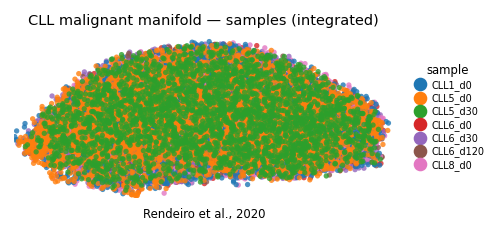

In [14]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('CLL malignant manifold — samples (integrated)', size=7.5)
ax.text(.5, -.12, 'Rendeiro et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight'); plt.show()
print('saved processed.h5ad', adata.shape, '+ samples.pdf')